# Student's t Distribution

This notebook accompanies [Student's t Distribution](../../notes/sampling_and_sampling_distributions/student_t_distribution.md). We construct $T=Z/\sqrt{V/\nu}$, compare its tails to the normal, and see why it is the right reference distribution when $\sigma$ is estimated.

## Construction from a normal and a chi-square

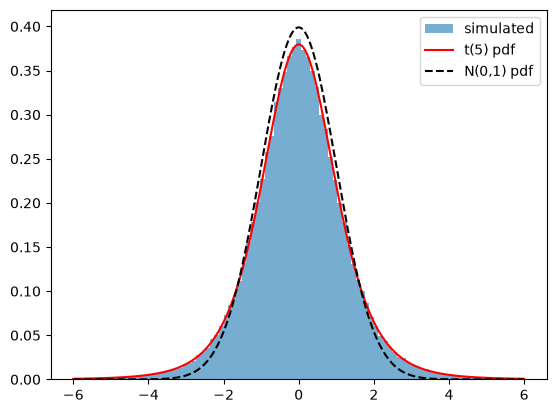

variance sim: 1.668  theory nu/(nu-2) = 1.667


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

nu = 5
z = rng.standard_normal(200_000)
v = rng.chisquare(nu, 200_000)
t_sim = z / np.sqrt(v / nu)

xs = np.linspace(-6, 6, 400)
plt.hist(t_sim, bins=np.linspace(-6, 6, 100), density=True, alpha=0.6, label="simulated")
plt.plot(xs, stats.t.pdf(xs, nu), "r", label=f"t({nu}) pdf")
plt.plot(xs, stats.norm.pdf(xs), "k--", label="N(0,1) pdf")
plt.legend(); plt.show()
print("variance sim:", round(t_sim.var(), 3), " theory nu/(nu-2) =", round(nu / (nu - 2), 3))

## Formulas versus `scipy.stats`

The density $\frac{\Gamma((\nu+1)/2)}{\sqrt{\nu\pi}\Gamma(\nu/2)}(1+x^2/\nu)^{-(\nu+1)/2}$ and the CDF via the regularized incomplete beta function, $F(t)=1-\tfrac12I_{\nu/(t^2+\nu)}(\nu/2,\tfrac12)$ for $t>0$.

In [2]:
from scipy.special import gamma, betainc

x = np.linspace(0.05, 6, 120)
for nu_ in (2, 5, 30):
    pdf_f = gamma((nu_ + 1) / 2) / (np.sqrt(nu_ * np.pi) * gamma(nu_ / 2)) * (1 + x ** 2 / nu_) ** (-(nu_ + 1) / 2)
    cdf_f = 1 - 0.5 * betainc(nu_ / 2, 0.5, nu_ / (x ** 2 + nu_))
    print(nu_, np.allclose(pdf_f, stats.t.pdf(x, nu_)), np.allclose(cdf_f, stats.t.cdf(x, nu_)))

2 True True
5 True True
30 True True


## Heavier tails

The 97.5th percentile and the tail probability $P(T>2)$ approach the normal values as $\nu$ grows.

In [3]:
print(f"{'nu':>5} {'t_0.975':>8} {'P(T>2)':>8}")
for nu_ in (1, 2, 5, 10, 30, 100):
    print(f"{nu_:>5} {stats.t.ppf(0.975, nu_):>8.3f} {stats.t.sf(2, nu_):>8.4f}")
print(f"{'inf':>5} {stats.norm.ppf(0.975):>8.3f} {stats.norm.sf(2):>8.4f}")

   nu  t_0.975   P(T>2)
    1   12.706   0.1476
    2    4.303   0.0918
    5    2.571   0.0510
   10    2.228   0.0367
   30    2.042   0.0273
  100    1.984   0.0241
  inf    1.960   0.0228


## Why the $t$ is needed: coverage with estimated $\sigma$

For normal samples of size $n=5$ the interval $\bar x\pm z_{0.975}\,s/\sqrt n$ covers $\mu$ less often than $95\%$ because $s$ is itself random. Replacing $z$ by $t_{0.975}(n-1)$ restores the coverage.

In [4]:
n, reps = 5, 50_000
data = rng.normal(10, 3, size=(reps, n))
xbar, s = data.mean(axis=1), data.std(axis=1, ddof=1)
se = s / np.sqrt(n)
for name, crit in (("z (1.96)", stats.norm.ppf(0.975)), (f"t ({stats.t.ppf(0.975, n-1):.3f})", stats.t.ppf(0.975, n - 1))):
    cover = np.mean(np.abs(xbar - 10) <= crit * se)
    print(f"{name:>12}: coverage = {cover:.4f}")

    z (1.96): coverage = 0.8780
   t (2.776): coverage = 0.9481


## Two-sample comparison from the note

Diet A: $n_1=20$, mean 120, $s_1=8$. Diet B: $n_2=25$, mean 130, $s_2=10$. We compute the Welch statistic and degrees of freedom by hand and check with `scipy.stats.ttest_ind_from_stats`. We also compare to the pooled-variance test.

In [5]:
m1, s1, n1 = 120, 8, 20
m2, s2, n2 = 130, 10, 25
v1, v2 = s1 ** 2 / n1, s2 ** 2 / n2
t_w = (m1 - m2) / np.sqrt(v1 + v2)
df_w = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))
print(f"Welch t = {t_w:.3f}, df = {df_w:.2f}, two-sided p = {2 * stats.t.sf(abs(t_w), df_w):.5f}")
print("scipy Welch :", stats.ttest_ind_from_stats(m1, s1, n1, m2, s2, n2, equal_var=False))
print("scipy pooled:", stats.ttest_ind_from_stats(m1, s1, n1, m2, s2, n2, equal_var=True))

Welch t = -3.727, df = 43.00, two-sided p = 0.00056
scipy Welch : Ttest_indResult(statistic=np.float64(-3.7267799624996494), pvalue=np.float64(0.0005614040814403743))
scipy pooled: Ttest_indResult(statistic=np.float64(-3.6349526850587117), pvalue=np.float64(0.000737820095635871))
